# Pokémon Battle Prediction · Random forest

**Task.** Predict whether Player 1 wins (`player_won = 1`) from Player 1's full team, Player 2's lead Pokémon and the first 30 turns of each Gen 2 OU battle.

**Approach.** A random forest on features of its own, different from those of the main notebook: besides the state at turn 30, they describe how the 30 turns were played. Version 1 (submission 1) uses 47 features; version 2 (submission 2) adds the condition of each team, type effectiveness, moves and species, and combines the forest with a logistic score (stacking). Every choice is validated on the same 5 folds as the main notebook.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/sample_submission.csv
/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/test.jsonl
/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/train.jsonl
/kaggle/input/competitions/fds-pokemon-battles-prediction-2026/type_chart_gen2.csv


## Data loading

Same data and checks as the main notebook. This notebook builds its own features and uses a random forest.

In [2]:
import json
import collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

SEED = 42
data_path = Path('/kaggle/input/competitions/fds-pokemon-battles-prediction-2026')


def load_battles(file_path):
    '''Parse a JSONL file (one battle per line) into a list of dictionaries.'''
    with open(file_path, 'r', encoding='utf-8') as f:
        battles = [json.loads(line) for line in f]
    print(f"{file_path.name}: {len(battles)} battles loaded.")
    return battles


train_data = load_battles(data_path / 'train.jsonl')
test_data = load_battles(data_path / 'test.jsonl')
sample_submission = pd.read_csv(data_path / 'sample_submission.csv')

assert all('player_won' in b for b in train_data) and all('player_won' not in b for b in test_data)
assert set(sample_submission['battle_id']) == {b['battle_id'] for b in test_data}
print("Checks passed.")

train.jsonl: 10000 battles loaded.
test.jsonl: 5000 battles loaded.
Checks passed.


## Battle state at turn 30

As a reference point, seven features describe the battle at the last observed turn: the remaining HP of each team in "full Pokémon" (6 = all six at full HP; Pokémon not yet seen count as full HP), their difference, the Pokémon lost by each player and the HP of the two active Pokémon.

In [3]:
def last_seen_hp(timeline, side):
    '''Last recorded HP of every Pokémon of one side that appeared in the given turns.'''
    hp = {}
    for turn in timeline:
        state = turn[f'{side}_pokemon_state']
        hp[state['name']] = state['hp_pct']
    return hp


def team_hp(timeline, side, p1_team):
    '''Remaining HP of a whole team in "full Pokémon"; unseen Pokémon count as full HP.'''
    hp = last_seen_hp(timeline, side)
    if side == 'p1':
        return sum(hp.get(name, 1.0) for name in p1_team)
    return sum(hp.values()) + (6 - len(hp))


def fainted(timeline, side):
    '''Number of Pokémon of one side whose last recorded HP is 0.'''
    return sum(value == 0 for value in last_seen_hp(timeline, side).values())


def create_state_features(data):
    '''State of the battle at turn 30. Each value depends on a single battle only,
    so applying the function to the test set cannot leak information.'''
    rows = []
    for battle in data:
        timeline = battle['battle_timeline']
        p1_team = [p['name'] for p in battle['p1_team_details']]
        features = {
            'p1_team_hp': team_hp(timeline, 'p1', p1_team),
            'p2_team_hp': team_hp(timeline, 'p2', p1_team),
        }
        features['team_hp_diff'] = features['p1_team_hp'] - features['p2_team_hp']
        features['p1_fainted'] = fainted(timeline, 'p1')
        features['p2_fainted'] = fainted(timeline, 'p2')
        features['p1_active_hp'] = timeline[-1]['p1_pokemon_state']['hp_pct']
        features['p2_active_hp'] = timeline[-1]['p2_pokemon_state']['hp_pct']

        features['battle_id'] = battle['battle_id']
        if 'player_won' in battle:
            features['player_won'] = int(battle['player_won'])
        rows.append(features)
    return pd.DataFrame(rows)


train_df = create_state_features(train_data)
test_df = create_state_features(test_data)
y = train_df['player_won']

state_features = [col for col in train_df.columns if col not in ['battle_id', 'player_won']]
print("State features:", len(state_features))
display(train_df[state_features].describe().T[['mean', 'std', 'min', 'max']].round(2))

State features: 7


,mean,std,min,max
p1_team_hp,3.43,1.33,0.00,6.0
p2_team_hp,4.00,1.05,0.34,6.0
team_hp_diff,-0.57,1.16,-5.51,4.0
p1_fainted,1.69,1.43,0.00,6.0
p2_fainted,0.50,0.77,0.00,5.0
p1_active_hp,0.67,0.33,0.00,1.0
p2_active_hp,0.70,0.30,0.00,1.0


## New features: how the battle was played

The state at turn 30 says where the battle stands, not how it got there. The first group of new features describes momentum and damage:
- the difference in team HP and in Pokémon lost at turns 10 and 20;
- the damage dealt by each player (HP lost by the opposing Pokémon while it stays on the field), the largest single hit and the damage of the last five turns;
- the HP recovered by each player (Leftovers, Recover, Rest, ...).

In [4]:
def add_damage_features(data, base_df):
    rows = []
    for battle in data:
        timeline = battle['battle_timeline']
        p1_team = [p['name'] for p in battle['p1_team_details']]
        features = {}

        # Momentum: how the advantage looked earlier in the battle
        for t in (10, 20):
            window = timeline[:t]
            features[f'team_hp_diff_t{t}'] = team_hp(window, 'p1', p1_team) - team_hp(window, 'p2', p1_team)
            features[f'fainted_diff_t{t}'] = fainted(window, 'p2') - fainted(window, 'p1')

        # Damage dealt and HP recovered, turn by turn, only while the same Pokémon stays on the field
        for side, opponent in (('p1', 'p2'), ('p2', 'p1')):
            damage, largest_hit, damage_last5, healing = 0.0, 0.0, 0.0, 0.0
            for k in range(1, len(timeline)):
                before, after = timeline[k - 1][f'{opponent}_pokemon_state'], timeline[k][f'{opponent}_pokemon_state']
                if before['name'] == after['name'] and after['hp_pct'] < before['hp_pct']:
                    hit = before['hp_pct'] - after['hp_pct']
                    damage += hit
                    largest_hit = max(largest_hit, hit)
                    if k >= len(timeline) - 5:
                        damage_last5 += hit
                own_before, own_after = timeline[k - 1][f'{side}_pokemon_state'], timeline[k][f'{side}_pokemon_state']
                if own_before['name'] == own_after['name'] and own_after['hp_pct'] > own_before['hp_pct']:
                    healing += own_after['hp_pct'] - own_before['hp_pct']
            features[f'{side}_damage_dealt'] = damage
            features[f'{side}_healing'] = healing
            features[f'{side}_max_hit'] = largest_hit
            features[f'{side}_damage_last5'] = damage_last5

        features['damage_diff'] = features['p1_damage_dealt'] - features['p2_damage_dealt']
        features['damage_last5_diff'] = features['p1_damage_last5'] - features['p2_damage_last5']
        rows.append(features)

    return pd.concat([base_df, pd.DataFrame(rows, index=base_df.index)], axis=1)


train_df = add_damage_features(train_data, train_df)
test_df = add_damage_features(test_data, test_df)
print("Train shape:", train_df.shape, " Test shape:", test_df.shape)

Train shape: (10000, 23)  Test shape: (5000, 22)


In [5]:
# Species -> types, from the training set only (the target is not used)
species_types = {}
for battle in train_data:
    for pokemon in battle['p1_team_details'] + [battle['p2_lead_details']]:
        species_types[pokemon['name']] = pokemon['types']

STATS = ['base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe']
CONDITIONS = {'turns_asleep': 'slp', 'turns_paralyzed': 'par'}
EFFECTS = {'turns_substitute': 'substitute', 'turns_seeded': 'leechseed', 'turns_confused': 'confusion'}


def add_style_features(data, base_df):
    '''Play style, turns spent under each condition and team information.

    Each value depends on a single battle (plus the species table built on the training set).
    '''
    rows = []
    for battle in data:
        timeline = battle['battle_timeline']
        p1_types = {p['name']: p['types'] for p in battle['p1_team_details']}
        features = {}

        for side, opponent in (('p1', 'p2'), ('p2', 'p1')):
            counts = collections.Counter()
            for k, turn in enumerate(timeline):
                move = turn[f'{side}_move_details']
                state = turn[f'{side}_pokemon_state']

                if move is None:                       # no move recorded: the player switched
                    counts['switches'] += 1
                else:
                    counts['priority_moves'] += move['priority'] > 0
                    if move['category'] == 'status':
                        counts['status_moves'] += 1
                    else:
                        counts['attacks'] += 1
                        own_types = p1_types.get(state['name']) if side == 'p1' else species_types.get(state['name'], [])
                        counts['stab_attacks'] += bool(own_types) and move['type'] in own_types
                        # Attack with no visible damage on the same opposing Pokémon
                        if k > 0:
                            before, after = timeline[k - 1][f'{opponent}_pokemon_state'], turn[f'{opponent}_pokemon_state']
                            counts['attacks_no_damage'] += (before['name'] == after['name']
                                                            and after['hp_pct'] >= before['hp_pct'])

                # Stat boosts gained while the same Pokémon stays on the field
                previous = timeline[k - 1][f'{side}_pokemon_state'] if k > 0 else None
                if previous is not None and previous['name'] == state['name']:
                    counts['boost_gain'] += sum(max(0, state['boosts'][s] - previous['boosts'][s]) for s in state['boosts'])

                for name, status in CONDITIONS.items():
                    counts[name] += state['status'] == status
                for name, effect in EFFECTS.items():
                    counts[name] += effect in state['effects']

            features[f'{side}_switches'] = counts['switches']
            features[f'{side}_status_moves'] = counts['status_moves']
            features[f'{side}_stab_share'] = counts['stab_attacks'] / counts['attacks'] if counts['attacks'] else 0.0
            features[f'{side}_priority_moves'] = counts['priority_moves']
            features[f'{side}_boost_gain'] = counts['boost_gain']
            for name in list(CONDITIONS) + list(EFFECTS):
                features[f'{side}_{name}'] = counts[name]
            features[f'{side}_attacks_no_damage'] = counts['attacks_no_damage']

        # Team information
        features['p1_used'] = len(last_seen_hp(timeline, 'p1'))
        features['p2_revealed'] = len(last_seen_hp(timeline, 'p2'))
        features['p1_leftovers'] = sum(p.get('item') == 'leftovers' for p in battle['p1_team_details'])
        features['p1_mean_bst'] = np.mean([sum(p[s] for s in STATS) for p in battle['p1_team_details']])
        rows.append(features)

    return pd.concat([base_df, pd.DataFrame(rows, index=base_df.index)], axis=1)


train_df = add_style_features(train_data, train_df)
test_df = add_style_features(test_data, test_df)

all_features = [col for col in train_df.columns if col not in ['battle_id', 'player_won']]
new_features = [col for col in all_features if col not in state_features]
X_state, X_test_state = train_df[state_features], test_df[state_features]
X_all, X_test_all = train_df[all_features], test_df[all_features]

print(f"State features: {len(state_features)}   New features: {len(new_features)}   Total: {len(all_features)}")
print("Train shape:", X_all.shape, " Test shape:", X_test_all.shape)

State features: 7   New features: 40   Total: 47
Train shape: (10000, 47)  Test shape: (5000, 47)


### How informative are the new features?

First, the correlation with the outcome of the 20 most correlated new features; then Player 1's win rate by the difference in damage dealt (groups with fewer than 100 battles are not drawn).

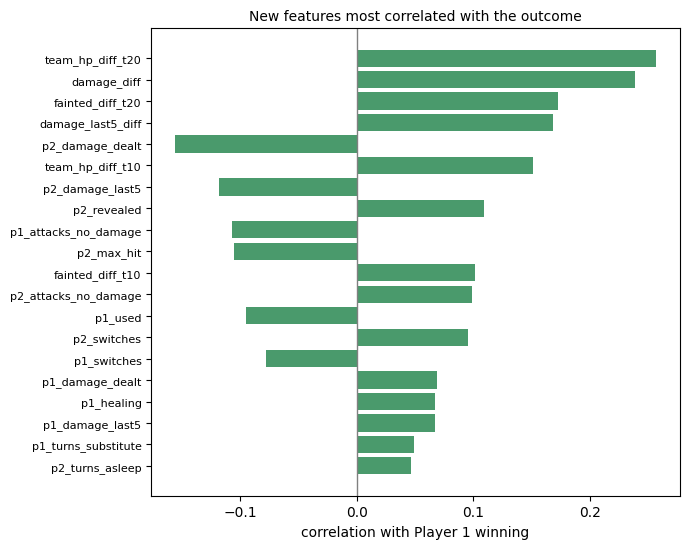

In [6]:
correlation = X_all[new_features].corrwith(y)
top_correlation = correlation.reindex(correlation.abs().sort_values().index).tail(20)

fig, ax = plt.subplots(figsize=(7, 5.6))
ax.barh(top_correlation.index, top_correlation.values, color='#4A9A6C')
ax.axvline(0, color='grey', linewidth=1)
ax.set_xlabel('correlation with Player 1 winning')
ax.set_title('New features most correlated with the outcome', fontsize=10)
ax.tick_params(axis='y', labelsize=8)
fig.tight_layout()
plt.show()

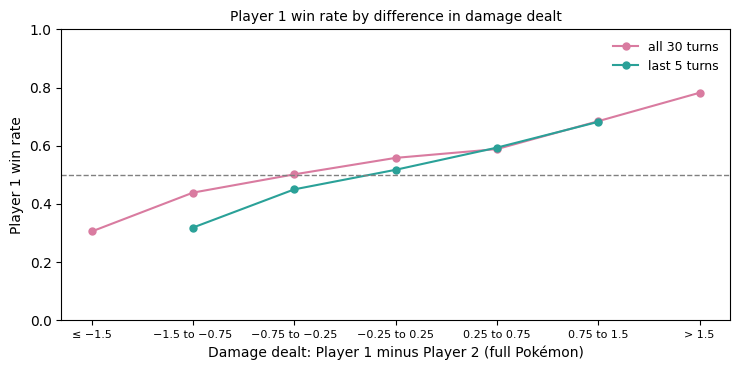

damage_diff - battles per group: [1629, 2038, 2030, 1962, 1319, 811, 211]
damage_last5_diff - battles per group: [73, 766, 2265, 5080, 1574, 239, 3]


In [7]:
damage_bins = [-np.inf, -1.5, -0.75, -0.25, 0.25, 0.75, 1.5, np.inf]
damage_labels = ['≤ −1.5', '−1.5 to −0.75', '−0.75 to −0.25', '−0.25 to 0.25', '0.25 to 0.75', '0.75 to 1.5', '> 1.5']

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for column, label, color in (('damage_diff', 'all 30 turns', '#D97BA0'),
                             ('damage_last5_diff', 'last 5 turns', '#2AA198')):
    groups = pd.cut(X_all[column], bins=damage_bins, labels=damage_labels)
    win_rate = y.groupby(groups, observed=False).mean().reindex(damage_labels).to_numpy(dtype=float, copy=True)
    battles = groups.value_counts().reindex(damage_labels).to_numpy()
    win_rate[battles < 100] = np.nan   # hide groups that are too small to give a reliable rate
    ax.plot(damage_labels, win_rate, marker='o', markersize=5, color=color, label=label)
ax.axhline(0.5, color='grey', linestyle='--', linewidth=1)
ax.set_ylim(0, 1)
ax.set_xlabel('Damage dealt: Player 1 minus Player 2 (full Pokémon)')
ax.set_ylabel('Player 1 win rate')
ax.set_title('Player 1 win rate by difference in damage dealt', fontsize=10)
ax.tick_params(axis='x', labelsize=8)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

for column in ('damage_diff', 'damage_last5_diff'):
    groups = pd.cut(X_all[column], bins=damage_bins, labels=damage_labels)
    print(column, "- battles per group:", groups.value_counts().reindex(damage_labels).tolist())

The strongest new features describe momentum and damage: the HP difference at turn 20 (correlation about 0.26) and the difference in damage dealt (about 0.24). Player 1 wins about 30% of the battles in which Player 2 dealt at least 1.5 Pokémon of damage more, and about 78% in the opposite case.

## Validation

Same 5 stratified folds as the main notebook. We compare two random forests with scikit-learn's default settings (100 trees, fully grown, √(number of features) features per split): one on the 7 state features only, one on the state features plus the 40 new ones.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

forest = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
scores_state = cross_val_score(forest, X_state, y, cv=cv, scoring='accuracy')
scores_all = cross_val_score(forest, X_all, y, cv=cv, scoring='accuracy')

comparison = pd.DataFrame({
    'state features': scores_state,
    'state + new features': scores_all,
}, index=[f'fold {k}' for k in range(1, 6)])
comparison['difference (points)'] = 100 * (comparison['state + new features'] - comparison['state features'])
display(comparison.style.format({'state features': '{:.2%}', 'state + new features': '{:.2%}',
                                 'difference (points)': '{:+.2f}'}))

print(f"State features only:   {scores_state.mean():.2%} (std across folds {scores_state.std():.2%})")
print(f"State + new features:  {scores_all.mean():.2%} (std across folds {scores_all.std():.2%})")
print(f"The new features help in {(scores_all > scores_state).sum()} of 5 folds")

,state features,state + new features,difference (points)
fold 1,64.80%,65.10%,+0.30
fold 2,63.80%,65.50%,+1.70
fold 3,63.25%,64.50%,+1.25
fold 4,63.45%,66.05%,+2.60
fold 5,63.65%,65.85%,+2.20


State features only:   63.79% (std across folds 0.54%)
State + new features:  65.40% (std across folds 0.55%)
The new features help in 5 of 5 folds


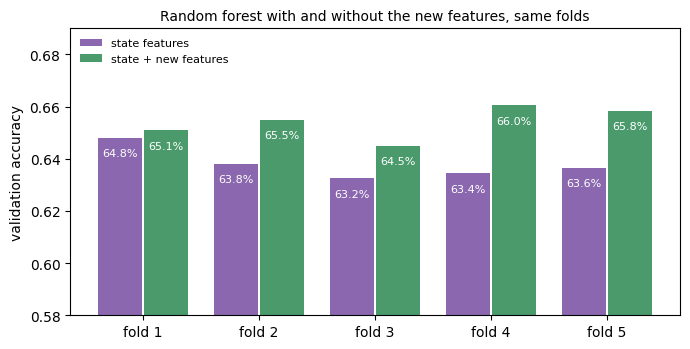

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
positions = np.arange(5)
for offset, fold_scores, label, color in ((-0.2, scores_state, 'state features', '#8A67AE'),
                                          (0.2, scores_all, 'state + new features', '#4A9A6C')):
    ax.bar(positions + offset, fold_scores, 0.38, color=color, label=label, zorder=2)
    for x_pos, value in zip(positions + offset, fold_scores):
        ax.text(x_pos, value - 0.004, f"{value:.1%}", ha='center', va='top', fontsize=8, color='white', zorder=3)
ax.set_xticks(positions, [f'fold {k}' for k in range(1, 6)])
ax.set_ylim(0.58, 0.69)
ax.set_ylabel('validation accuracy')
ax.set_title('Random forest with and without the new features, same folds', fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

The new features raise the accuracy from about 63.79% to about 65.40%, with a gain in all five folds (from 0.3 to 2.6 points).

## Checking the default settings

We check two settings with `GridSearchCV` on the same folds: `max_features` (`sqrt` or `log2` of the number of features per split) and `min_samples_leaf` (1, 5 or 20 battles per leaf). The training accuracy is shown too.

In [10]:
forest_search = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    param_grid={'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 5, 20]},
    cv=cv, scoring='accuracy', return_train_score=True,
)
forest_search.fit(X_all, y)

search_results = pd.DataFrame(forest_search.cv_results_)[
    ['param_max_features', 'param_min_samples_leaf', 'mean_train_score', 'mean_test_score', 'std_test_score']
].sort_values('mean_test_score', ascending=False)
search_results.columns = ['max_features', 'min_samples_leaf', 'training accuracy',
                          'validation accuracy', 'std across folds']
display(search_results.style.format({'training accuracy': '{:.2%}', 'validation accuracy': '{:.2%}',
                                     'std across folds': '{:.2%}'}).hide(axis='index'))

spread = search_results['validation accuracy'].max() - search_results['validation accuracy'].min()
print(f"Range of validation accuracy across the grid: {100 * spread:.2f} points")

max_features,min_samples_leaf,training accuracy,validation accuracy,std across folds
sqrt,5,95.31%,65.84%,0.75%
log2,20,76.76%,65.71%,0.67%
log2,5,94.70%,65.61%,0.65%
log2,1,100.00%,65.54%,0.32%
sqrt,1,100.00%,65.40%,0.55%
sqrt,20,77.00%,65.25%,0.70%


Range of validation accuracy across the grid: 0.59 points


All six combinations are within about 0.6 points (65.25% to 65.84%), about as much as the variation between folds. Fully grown trees fit the training battles perfectly (100% training accuracy) and still validate as well as simpler ones, because averaging many different trees removes most of their overfitting. Since picking the best combination on the same folds would make its score optimistic, we keep the default settings.

## Which features the forest uses

Importance of each feature in the final forest (mean decrease in impurity). purple = state features, green = new features. This measure favours continuous features, so it is an indication rather than an exact ranking.

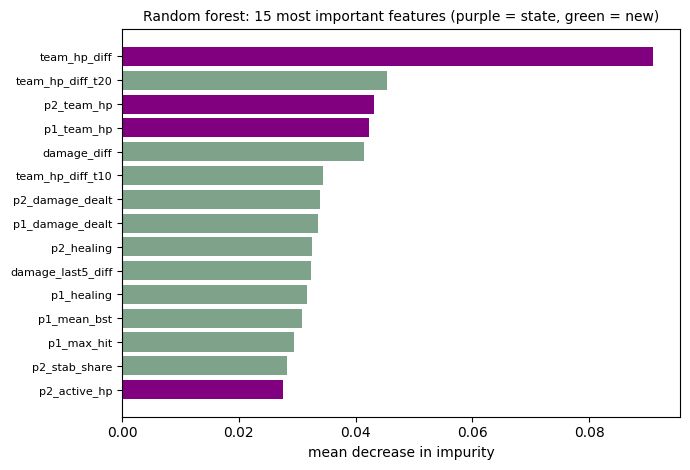

Share of the total importance assigned to the new features: 75%


In [11]:
# Final model of version 1: default forest refitted on all 10,000 training battles
final_forest = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
final_forest.fit(X_all, y)

importances = pd.Series(final_forest.feature_importances_, index=all_features).sort_values()
top = importances.tail(15)

fig, ax = plt.subplots(figsize=(7, 4.8))
colors = ['#800080' if name in state_features else '#7FA38A' for name in top.index]
ax.barh(top.index, top.values, color=colors)
ax.set_xlabel('mean decrease in impurity')
ax.set_title('Random forest: 15 most important features (purple = state, green = new)', fontsize=10)
ax.tick_params(axis='y', labelsize=8)
fig.tight_layout()
plt.show()

share_new = importances[new_features].sum()
print(f"Share of the total importance assigned to the new features: {share_new:.0%}")

### Submission 1 · Random forest (version 1)

Random forest with the default settings on the 47 features (7 state + 40 new), refitted on all 10,000 labelled battles. Cross-validated accuracy is about 65.4%. Saved as `submission_rf_v1.csv`.

In [12]:
test_predictions = final_forest.predict(X_test_all)

# Predictions of version 1, matched to the template by battle_id
predictions_by_id = pd.Series(test_predictions, index=test_df['battle_id'])
submission_df = sample_submission.copy()
submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id)

if submission_df['player_won'].isna().any():
    raise ValueError("Some battle_ids have no prediction.")

submission_df['player_won'] = submission_df['player_won'].astype(int)
submission_df.to_csv('submission_rf_v1.csv', index=False)

print("submission_rf_v1.csv created:", submission_df.shape)
print(f"Predicted Player 1 win rate on test: {submission_df['player_won'].mean():.1%}")
display(submission_df.head())

submission_rf_v1.csv created: (5000, 2)
Predicted Player 1 win rate on test: 50.6%


,battle_id,player_won
0,0,1
1,1,0
2,2,1
3,3,0
4,4,1


## Version 2 · Team condition, type effectiveness, moves and species

Three groups of features are added to version 1:
- **A. Condition of each team at turn 30**: the HP of the six Pokémon sorted from healthiest to weakest, the number of Pokémon with low, medium and high HP, the *usable HP* (alive and not asleep or frozen), the HP weighted by base stat total, the status counts, and the status and boosts of the active Pokémon.
- **B. Type effectiveness of the attacks**, from the supplied Gen 2 type chart: super effective, resisted and no-effect hits, and mean base power.
- **C. Moves and species**: uses of the 58 most frequent moves and remaining HP of the 41 most frequent species, for each player (198 sparse columns).



In [13]:
type_chart = pd.read_csv(data_path / 'type_chart_gen2.csv')
type_multiplier = {(row.attacking_type, row.defending_type): row.multiplier
                   for row in type_chart.itertuples(index=False)}


def effectiveness(move_type, defender_types):
    '''Damage multiplier of a move type against a Pokémon with the given types.'''
    multiplier = 1.0
    for defending_type in defender_types:
        if defending_type != 'notype':
            multiplier *= type_multiplier.get((move_type, defending_type), 1.0)
    return multiplier


# Lookup tables from the training set only (no target involved)
base_stat_total = {}
for battle in train_data:
    for pokemon in battle['p1_team_details'] + [battle['p2_lead_details']]:
        base_stat_total[pokemon['name']] = sum(pokemon[s] for s in STATS)
mean_bst = float(np.mean(list(base_stat_total.values())))

move_usage = collections.Counter(
    turn[f'{side}_move_details']['name']
    for battle in train_data for turn in battle['battle_timeline'] for side in ('p1', 'p2')
    if turn[f'{side}_move_details']
)
frequent_moves = sorted(name for name, count in move_usage.items() if count >= 1000)
species_count = collections.Counter(p['name'] for battle in train_data for p in battle['p1_team_details'])
frequent_species = sorted(name for name, count in species_count.items() if count >= 150)
print(f"Frequent moves: {len(frequent_moves)}   Frequent species: {len(frequent_species)}")

STATUSES = ['slp', 'par', 'tox', 'psn', 'brn', 'frz']


def team_at_turn30(battle, side):
    '''(name, HP, status) of the six Pokémon of one side at turn 30.

    Player 2's Pokémon not yet revealed are unknown (name None), at full HP and with no status.
    '''
    hp, status = {}, {}
    for turn in battle['battle_timeline']:
        state = turn[f'{side}_pokemon_state']
        hp[state['name']] = state['hp_pct']
        status[state['name']] = state['status']
    if side == 'p1':
        names = [p['name'] for p in battle['p1_team_details']]
    else:
        names = list(hp) + [None] * (6 - len(hp))
    return [(name, hp.get(name, 1.0), status.get(name, 'nostatus')) for name in names]


def add_version2_features(data, base_df):
    '''Groups A (team condition), B (type effectiveness) and C (moves and species).

    Each value depends on a single battle plus the lookup tables built on the training set.
    '''
    rows = []
    for battle in data:
        timeline = battle['battle_timeline']
        p1_types = {p['name']: p['types'] for p in battle['p1_team_details']}
        features = {}

        # A. Condition of each team at turn 30
        for side in ('p1', 'p2'):
            team = team_at_turn30(battle, side)
            hp_values = [hp for _, hp, _ in team]
            for rank, value in enumerate(sorted(hp_values, reverse=True), start=1):
                features[f'{side}_hp_rank{rank}'] = value
            features[f'{side}_n_low'] = sum(0 < v <= 0.25 for v in hp_values)
            features[f'{side}_n_mid'] = sum(0.25 < v <= 0.75 for v in hp_values)
            features[f'{side}_n_high'] = sum(v > 0.75 for v in hp_values)
            features[f'{side}_usable_hp'] = sum(hp for _, hp, s in team if hp > 0 and s not in ('slp', 'frz'))
            features[f'{side}_weighted_hp'] = sum(hp * base_stat_total.get(name, mean_bst) / mean_bst
                                                  for name, hp, _ in team)
            for status in STATUSES:
                features[f'{side}_n_{status}'] = sum(s == status for _, _, s in team)
            last = timeline[-1][f'{side}_pokemon_state']
            features[f'{side}_active_status'] = int(last['status'] not in ('nostatus', 'fnt'))
            features[f'{side}_active_boosts'] = sum(last['boosts'].values())
        for name in ('n_low', 'n_mid', 'n_high', 'usable_hp', 'weighted_hp'):
            features[f'{name}_diff'] = features[f'p1_{name}'] - features[f'p2_{name}']

        # B. Type effectiveness of the attacks against the Pokémon hit
        for side, opponent in (('p1', 'p2'), ('p2', 'p1')):
            super_effective = resisted = no_effect = 0
            powers = []
            for turn in timeline:
                move = turn[f'{side}_move_details']
                if move and move['base_power'] > 0:
                    defender = turn[f'{opponent}_pokemon_state']['name']
                    defender_types = p1_types.get(defender) if opponent == 'p1' else species_types.get(defender, ['notype'])
                    multiplier = effectiveness(move['type'], defender_types or ['notype'])
                    super_effective += multiplier > 1
                    resisted += 0 < multiplier < 1
                    no_effect += multiplier == 0
                    powers.append(move['base_power'])
            features[f'{side}_super_effective'] = super_effective
            features[f'{side}_resisted'] = resisted
            features[f'{side}_no_effect'] = no_effect
            features[f'{side}_mean_power'] = np.mean(powers) if powers else 0.0

        # C. Moves used and remaining HP of the most frequent species
        for side in ('p1', 'p2'):
            used = collections.Counter(turn[f'{side}_move_details']['name'] for turn in timeline
                                       if turn[f'{side}_move_details'])
            for name in frequent_moves:
                features[f'{side}_move_{name}'] = used[name]
            last_hp = last_seen_hp(timeline, side)
            team = set(p1_types) if side == 'p1' else set(last_hp)   # for Player 2, only the Pokémon seen so far
            for name in frequent_species:
                features[f'{side}_species_{name}'] = last_hp.get(name, 1.0) if name in team else 0.0

        rows.append(features)

    return pd.concat([base_df, pd.DataFrame(rows, index=base_df.index)], axis=1)


train_df_v2 = add_version2_features(train_data, train_df)
test_df_v2 = add_version2_features(test_data, test_df)

v2_columns = [col for col in train_df_v2.columns if col not in train_df.columns]
sparse_features = [col for col in v2_columns if '_move_' in col or '_species_' in col]
dense_features = all_features + [col for col in v2_columns if col not in sparse_features]
features_v2 = dense_features + sparse_features

X_v2, X_test_v2 = train_df_v2[features_v2], test_df_v2[features_v2]
print(f"Version 1 features: {len(all_features)}   Groups A and B: {len(dense_features) - len(all_features)}   "
      f"Group C (moves and species): {len(sparse_features)}   Total: {len(features_v2)}")
print("Train shape:", X_v2.shape, " Test shape:", X_test_v2.shape)

Frequent moves: 58   Frequent species: 41
Version 1 features: 47   Groups A and B: 51   Group C (moves and species): 198   Total: 296
Train shape: (10000, 296)  Test shape: (5000, 296)


### How informative are the new features?

Correlation with the outcome of the 15 most correlated features of groups A and B.

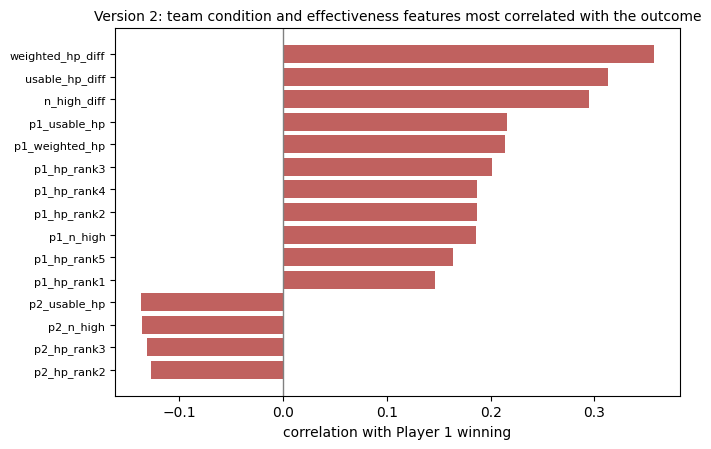

For comparison, team_hp_diff (version 1): 0.374


In [14]:
group_ab = [col for col in dense_features if col not in all_features]
correlation_v2 = X_v2[group_ab].corrwith(y)
top_correlation_v2 = correlation_v2.reindex(correlation_v2.abs().sort_values().index).tail(15)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(top_correlation_v2.index, top_correlation_v2.values, color='#C0615F')
ax.axvline(0, color='grey', linewidth=1)
ax.set_xlabel('correlation with Player 1 winning')
ax.set_title('Version 2: team condition and effectiveness features most correlated with the outcome', fontsize=10)
ax.tick_params(axis='y', labelsize=8)
fig.tight_layout()
plt.show()

print(f"For comparison, team_hp_diff (version 1): {X_v2['team_hp_diff'].corr(y):.3f}")

The strongest new features are differences between the two teams: HP weighted by base stats (correlation about 0.36), usable HP (0.31) and Pokémon with high HP (0.29). They are close to the plain HP difference of version 1 (0.37) and refine it: they say which Pokémon still have HP and whether they can act.

### Validation of version 2

The default forest of version 1 with groups A and B, then also with group C. As a reference, a standardised logistic regression on the same 296 features.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

scores_v2_ab = cross_val_score(forest, X_v2[dense_features], y, cv=cv, scoring='accuracy')
scores_v2_raw = cross_val_score(forest, X_v2, y, cv=cv, scoring='accuracy')

logistic_v2 = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
scores_v2_logistic = cross_val_score(logistic_v2, X_v2, y, cv=cv, scoring='accuracy')

print(f"Random forest, version 1 (47 features):          {scores_all.mean():.2%}")
print(f"Random forest, + groups A and B ({len(dense_features)} features):  {scores_v2_ab.mean():.2%}")
print(f"Random forest, + group C ({len(features_v2)} features):        {scores_v2_raw.mean():.2%}")
print(f"Logistic regression on the same {len(features_v2)} features:   {scores_v2_logistic.mean():.2%}")

Random forest, version 1 (47 features):          65.40%
Random forest, + groups A and B (98 features):  65.72%
Random forest, + group C (296 features):        66.37%
Logistic regression on the same 296 features:   66.89%


Groups A and B add little to the forest (about 65.72%), and the raw group C columns a little more (about 66.37%). The logistic regression on the same 296 features does better (about 66.89%): a tree splits on one column at a time and handles hundreds of sparse, weak columns badly, while a linear model simply adds up their small effects. 

### Combining the forest with a logistic score (stacking)

With `StackingClassifier` the forest is the final model, and it receives as an extra feature the probability of a Player 1 win predicted by the logistic regression (`passthrough=True` keeps all the original features too). The score of the training battles is computed out of fold with an inner 5-fold split, so the forest never sees a score produced by a model trained on the same battle; the whole stack is refitted in each outer fold.

With about 300 columns, `sqrt` would let each split choose among only 17 of them, so the score would rarely be available: we use `max_features=0.2` (59 columns), `min_samples_leaf=5` and 300 trees, and compare them with the default settings. These settings were compared on the same folds, so the chosen one is slightly optimistic.

In [16]:
from sklearn.ensemble import StackingClassifier


def stacked_forest(max_features, min_samples_leaf):
    '''Random forest (final model) that also receives the out-of-fold logistic score.'''
    return StackingClassifier(
        estimators=[('logistic_score', make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)))],
        final_estimator=RandomForestClassifier(n_estimators=300, max_features=max_features,
                                               min_samples_leaf=min_samples_leaf, random_state=SEED, n_jobs=-1),
        passthrough=True,                                                 # the forest also sees all the original features
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),  # out-of-fold scores for the training battles
        stack_method='predict_proba',
    )


scores_stack_default = cross_val_score(stacked_forest('sqrt', 1), X_v2, y, cv=cv, scoring='accuracy')

forest_v2 = stacked_forest(0.2, 5)
scores_v2 = cross_val_score(forest_v2, X_v2, y, cv=cv, scoring='accuracy')

stack_settings = pd.DataFrame({
    'max_features': ['sqrt (17 columns)', '0.2 (59 columns)'],
    'min_samples_leaf': [1, 5],
    'validation accuracy': [scores_stack_default.mean(), scores_v2.mean()],
    'std across folds': [scores_stack_default.std(), scores_v2.std()],
})
display(stack_settings.style.format({'validation accuracy': '{:.2%}', 'std across folds': '{:.2%}'})
        .hide(axis='index'))

comparison_v2 = pd.DataFrame({
    'version 1': scores_all,
    'logistic regression': scores_v2_logistic,
    'version 2': scores_v2,
}, index=[f'fold {k}' for k in range(1, 6)])
comparison_v2['v2 − v1 (points)'] = 100 * (comparison_v2['version 2'] - comparison_v2['version 1'])
display(comparison_v2.style.format({'version 1': '{:.2%}', 'logistic regression': '{:.2%}',
                                    'version 2': '{:.2%}', 'v2 − v1 (points)': '{:+.2f}'}))

print(f"Version 1: {scores_all.mean():.2%}   Version 2: {scores_v2.mean():.2%} (std across folds {scores_v2.std():.2%})")
print(f"Version 2 is better than version 1 in {(scores_v2 > scores_all).sum()} of 5 folds "
      f"and better than the logistic regression alone in {(scores_v2 > scores_v2_logistic).sum()} of 5 folds")

max_features,min_samples_leaf,validation accuracy,std across folds
sqrt (17 columns),1,67.34%,0.63%
0.2 (59 columns),5,67.78%,0.92%


,version 1,logistic regression,version 2,v2 − v1 (points)
fold 1,65.10%,67.00%,67.85%,+2.75
fold 2,65.50%,67.95%,67.55%,+2.05
fold 3,64.50%,66.55%,67.15%,+2.65
fold 4,66.05%,68.50%,69.50%,+3.45
fold 5,65.85%,64.45%,66.85%,+1.00


Version 1: 65.40%   Version 2: 67.78% (std across folds 0.92%)
Version 2 is better than version 1 in 5 of 5 folds and better than the logistic regression alone in 4 of 5 folds


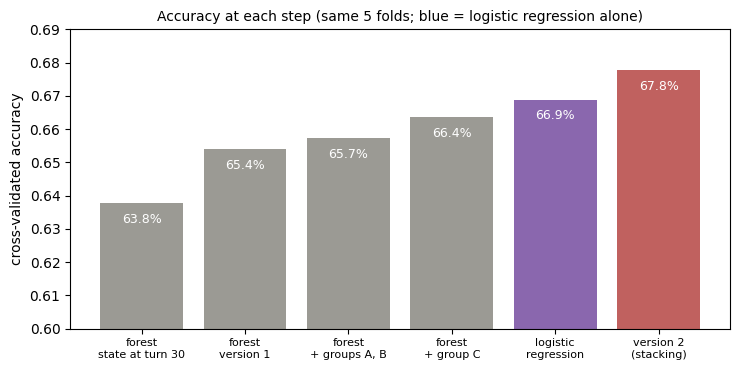

In [17]:
steps = pd.Series({
    'forest\nstate at turn 30': scores_state.mean(),
    'forest\nversion 1': scores_all.mean(),
    'forest\n+ groups A, B': scores_v2_ab.mean(),
    'forest\n+ group C': scores_v2_raw.mean(),
    'logistic\nregression': scores_v2_logistic.mean(),
    'version 2\n(stacking)': scores_v2.mean(),
})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = ['#9b9a94'] * 4 + ['#8A67AE', '#C0615F']
ax.bar(steps.index, steps.values, color=colors, zorder=2)
for k, value in enumerate(steps.values):
    ax.text(k, value - 0.003, f"{value:.1%}", ha='center', va='top', fontsize=9, color='white', zorder=3)
ax.set_ylim(0.6, 0.69)
ax.set_ylabel('cross-validated accuracy')
ax.set_title('Accuracy at each step (same 5 folds; blue = logistic regression alone)', fontsize=10)
ax.tick_params(axis='x', labelsize=8)
fig.tight_layout()
plt.show()

The stacked forest reaches about 67.78%: better than version 1 in all five folds and than the logistic regression alone in four. With the default settings the stack reaches about 67.34%. Neither model gets there alone: the forest starts from the logistic score and corrects it with thresholds and interactions.

### Which features the forest of version 2 uses

Importance of the features in the final forest of version 2: logistic score in dark grey, version 1 features in green, version 2 features in red.

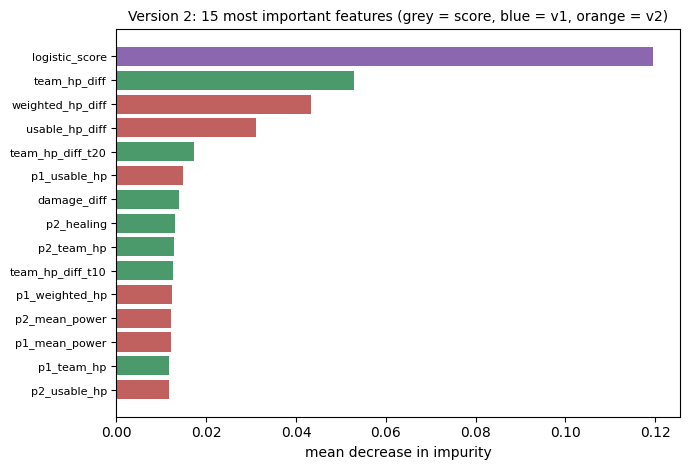

Share of the total importance: logistic score 12%, version 1 features 35%, version 2 features 53%


In [18]:
# Final model of version 2, refitted on all 10,000 training battles
forest_v2.fit(X_v2, y)

forest_inputs = ['logistic_score'] + features_v2   # with passthrough, the score comes first
importances_v2 = pd.Series(forest_v2.final_estimator_.feature_importances_, index=forest_inputs).sort_values()
top_v2 = importances_v2.tail(15)

fig, ax = plt.subplots(figsize=(7, 4.8))
colors = ['#8A67AE' if name == 'logistic_score' else '#4A9A6C' if name in all_features else '#C0615F'
          for name in top_v2.index]
ax.barh(top_v2.index, top_v2.values, color=colors)
ax.set_xlabel('mean decrease in impurity')
ax.set_title('Version 2: 15 most important features (grey = score, blue = v1, orange = v2)', fontsize=10)
ax.tick_params(axis='y', labelsize=8)
fig.tight_layout()
plt.show()

print(f"Share of the total importance: logistic score {importances_v2['logistic_score']:.0%}, "
      f"version 1 features {importances_v2[all_features].sum():.0%}, "
      f"version 2 features {importances_v2[v2_columns].sum():.0%}")

### Submission 2 · Random forest (version 2)

Stacked random forest (out-of-fold logistic score + 296 features, 300 trees, `max_features=0.2`, `min_samples_leaf=5`), refitted on all 10,000 labelled battles. Cross-validated accuracy is about 67.78%, against 65.34% for version 1, with a gain in all five folds.

In [19]:
test_predictions_v2 = forest_v2.predict(X_test_v2)

predictions_by_id = pd.Series(test_predictions_v2, index=test_df_v2['battle_id'])
submission_df = sample_submission.copy()
submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id)

if submission_df['player_won'].isna().any():
    raise ValueError("Some battle_ids have no prediction.")

submission_df['player_won'] = submission_df['player_won'].astype(int)
submission_df.to_csv('submission.csv', index=False)

print("submission.csv created:", submission_df.shape)
print(f"Predicted Player 1 win rate on test: {submission_df['player_won'].mean():.1%}")
display(submission_df.head())

submission.csv created: (5000, 2)
Predicted Player 1 win rate on test: 52.4%


,battle_id,player_won
0,0,1
1,1,0
2,2,0
3,3,0
4,4,1
